# Avaliação do algoritmo SVM em uma tarefa de classificação multiclasse

**Disciplina:** Aprendizado de Máquina
**Base de apoio:** MultiTarget Bioactivity ChEMBL — `chembl_activities.csv`

---

## Objetivo

Avaliar experimentalmente o comportamento do **Support Vector Machine (SVM)** em um problema
real de classificação multiclasse, verificando o impacto de:

1. **kernel** (linear, RBF, polinomial);
2. **hiperparâmetros** `C` e `gamma`;
3. **normalização** dos atributos;
4. **tamanho da amostra** sobre desempenho e custo computacional.

> A base de bioatividade é o **instrumento** do experimento. As conclusões do trabalho
> são sobre o **algoritmo**, não sobre química ou farmacologia.

## Tarefa de classificação

| Item | Descrição |
|---|---|
| Entrada | Estrutura química de uma molécula (SMILES → fingerprint) |
| Saída | Qual dos 4 alvos proteicos a molécula inibe |
| Classes | BACE1, DRD2, EGFR, HDAC1 |
| Tipo | Classificação multiclasse (4 classes, mutuamente exclusivas) |

## 1. Configuração do ambiente

In [2]:
try:
    import rdkit
except ImportError:
    %pip install -q rdkit


In [3]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10})

OUT = "resultados"
os.makedirs(OUT, exist_ok=True)

print("Ambiente configurado.")

Ambiente configurado.


## 2. Carga da base

A detecção do arquivo é automática: se o arquivo já existir localmente (ex.: na pasta `data/` ou no diretório atual) ou no ambiente Colab, ele é carregado diretamente. Caso não seja encontrado no Colab, a janela de upload será aberta automaticamente.

In [4]:
# Busca automática do arquivo em diretórios locais ou Google Colab
possiveis_caminhos = [
    'data/chembl_activities (1).csv',
    'data/chembl_activities.csv',
    'chembl_activities (1).csv',
    'chembl_activities.csv',
    'PPGCC_ML_SVG/data/chembl_activities (1).csv',
    'PPGCC_ML_SVG/data/chembl_activities.csv',
    '../data/chembl_activities (1).csv',
    '../data/chembl_activities.csv',
    '/content/chembl_activities.csv',
    '/content/chembl_activities (1).csv',
]

CAMINHO = None
for p in possiveis_caminhos:
    if os.path.exists(p):
        CAMINHO = p
        break

# Se não encontrado localmente, tenta upload no Google Colab
if CAMINHO is None:
    try:
        from google.colab import files
        print('Arquivo local não encontrado. Selecione o arquivo chembl_activities.csv para upload:')
        enviados = files.upload()
        if enviados:
            CAMINHO = list(enviados.keys())[0]
    except Exception as e:
        print('Upload do Colab não disponível:', e)

if CAMINHO is None or not os.path.exists(CAMINHO):
    raise FileNotFoundError(
        'Arquivo de dados não encontrado! '
        'Coloque chembl_activities.csv na pasta data/ ou realize o upload no Colab.'
    )

print('Arquivo carregado com sucesso:', os.path.abspath(CAMINHO))


Arquivo carregado com sucesso: c:\Users\luisfcabral\Documents\Projetos\UFPI\ML\PPGCC_ML_SVG\data\chembl_activities (1).csv


In [5]:
df_bruto = pd.read_csv(CAMINHO, low_memory=False)

print(f"Dimensões: {df_bruto.shape[0]:,} linhas x {df_bruto.shape[1]} colunas\n")
df_bruto.head()

Dimensões: 58,736 linhas x 14 colunas



,protein,activity_id,molecule_chembl_id,canonical_smiles,target_chembl_id,assay_chembl_id,assay_type,standard_type,standard_relation,standard_value,standard_units,pchembl_value,data_validity_comment,potential_duplicate
0,EGFR,32260,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,CHEMBL203,CHEMBL674637,B,IC50,=,41.0,nM,7.39,NaN,0
1,EGFR,32267,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,CHEMBL203,CHEMBL674637,B,IC50,=,170.0,nM,6.77,NaN,0
2,EGFR,32680,CHEMBL137635,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12,CHEMBL203,CHEMBL677833,B,IC50,=,9300.0,nM,5.03,NaN,0
3,EGFR,32780,CHEMBL77085,N#CC(C#N)=Cc1cc(O)ccc1[N+](=O)[O-],CHEMBL203,CHEMBL674643,B,IC50,=,96000.0,nM,4.02,NaN,0
4,EGFR,32781,CHEMBL77085,N#CC(C#N)=Cc1cc(O)ccc1[N+](=O)[O-],CHEMBL203,CHEMBL675636,B,Ki,=,24000.0,nM,4.62,NaN,0


In [6]:
print("ESTRUTURA DA BASE")
print("=" * 72)
for col in df_bruto.columns:
    print(f"{col:26s} {str(df_bruto[col].dtype):8s} "
          f"únicos={df_bruto[col].nunique():<7} nulos={df_bruto[col].isna().sum()}")

ESTRUTURA DA BASE
protein                    object   únicos=4       nulos=0
activity_id                int64    únicos=58736   nulos=0
molecule_chembl_id         object   únicos=37515   nulos=0
canonical_smiles           object   únicos=37474   nulos=49
target_chembl_id           object   únicos=4       nulos=0
assay_chembl_id            object   únicos=5213    nulos=0
assay_type                 object   únicos=1       nulos=0
standard_type              object   únicos=6       nulos=0
standard_relation          object   únicos=1       nulos=0
standard_value             float64  únicos=8620    nulos=0
standard_units             object   únicos=1       nulos=0
pchembl_value              float64  únicos=691     nulos=0
data_validity_comment      float64  únicos=0       nulos=58736
potential_duplicate        int64    únicos=2       nulos=0


## 3. Caracterização da base

Ponto central: **cada linha é uma medição experimental, não uma molécula.**
A mesma molécula aparece várias vezes, testada em ensaios diferentes.
Ignorar isso causaria **vazamento de dados** — a mesma molécula apareceria
simultaneamente no treino e no teste.

In [7]:
print(f"Registros de atividade     : {len(df_bruto):,}")
print(f"Moléculas únicas           : {df_bruto['molecule_chembl_id'].nunique():,}")
print(f"Medições por molécula      : {len(df_bruto)/df_bruto['molecule_chembl_id'].nunique():.2f}")
print(f"Ensaios distintos          : {df_bruto['assay_chembl_id'].nunique():,}")
print(f"\nAlvos proteicos:")
print(df_bruto.groupby(['protein', 'target_chembl_id']).size().to_string())
print(f"\nTipos de medida:")
print(df_bruto['standard_type'].value_counts().to_string())

Registros de atividade     : 58,736
Moléculas únicas           : 37,515
Medições por molécula      : 1.57
Ensaios distintos          : 5,213

Alvos proteicos:
protein  target_chembl_id
BACE1    CHEMBL4822          15698
DRD2     CHEMBL217           12816
EGFR     CHEMBL203           19866
HDAC1    CHEMBL325           10356

Tipos de medida:
standard_type
IC50    41511
Ki      14657
Kd       1175
EC50     1097
AC50      197
ED50       99


In [8]:
# Uma molécula pode se ligar a mais de um alvo? Isso define multiclasse vs multi-label.
n_alvos = df_bruto.groupby('molecule_chembl_id')['protein'].nunique()

print("Nº de alvos por molécula:")
print(n_alvos.value_counts().sort_index().to_string())
print(f"\nMoléculas multi-alvo: {(n_alvos > 1).sum()} ({(n_alvos > 1).mean():.2%})")
print("\nConclusão: a sobreposição é desprezível, portanto o problema é tratado")
print("como CLASSIFICAÇÃO MULTICLASSE (classes mutuamente exclusivas).")

Nº de alvos por molécula:
protein
1    37444
2       70
3        1

Moléculas multi-alvo: 71 (0.19%)

Conclusão: a sobreposição é desprezível, portanto o problema é tratado
como CLASSIFICAÇÃO MULTICLASSE (classes mutuamente exclusivas).


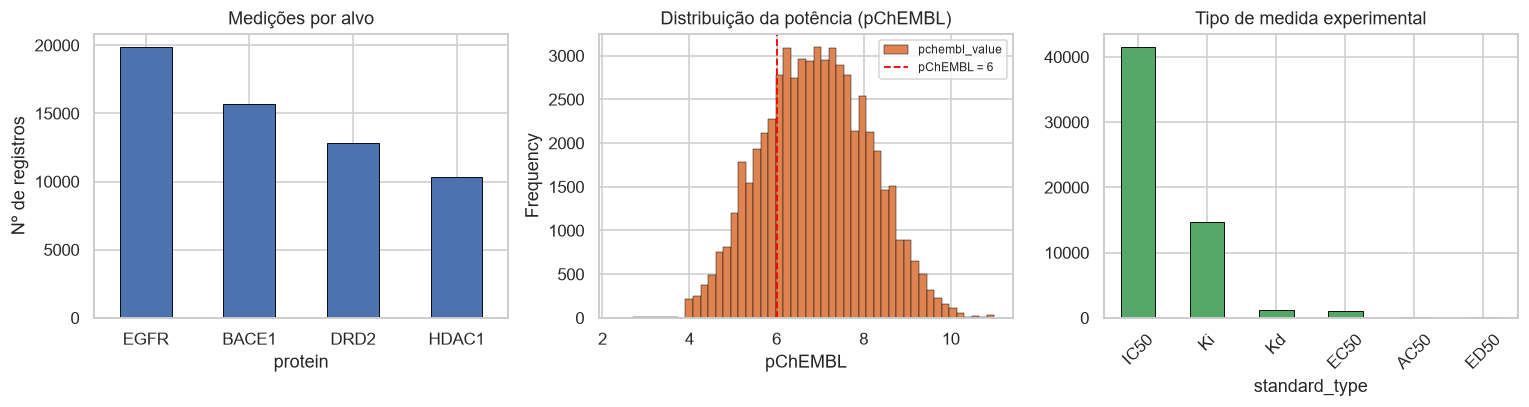

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))

cont_raw = df_bruto['protein'].value_counts()
cont_raw.plot(kind='bar', ax=ax[0], color='#4C72B0', edgecolor='black', linewidth=.6)
ax[0].set_title('Medições por alvo'); ax[0].set_ylabel('Nº de registros')
ax[0].tick_params(axis='x', rotation=0)

df_bruto['pchembl_value'].plot(kind='hist', bins=50, ax=ax[1],
                               color='#DD8452', edgecolor='black', linewidth=.3)
ax[1].axvline(6, color='red', ls='--', lw=1.2, label='pChEMBL = 6')
ax[1].set_title('Distribuição da potência (pChEMBL)')
ax[1].set_xlabel('pChEMBL'); ax[1].legend(fontsize=8)

df_bruto['standard_type'].value_counts().plot(kind='bar', ax=ax[2],
                                              color='#55A868', edgecolor='black', linewidth=.6)
ax[2].set_title('Tipo de medida experimental'); ax[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(f"{OUT}/caracterizacao_base.png", bbox_inches='tight')
plt.show()

## 4. Pré-processamento

Três passos, cada um com justificativa metodológica:

| Passo | Ação | Por quê |
|---|---|---|
| 1 | Agrupar por (molécula, alvo), tomando a **mediana** do pChEMBL | Elimina réplicas experimentais e evita vazamento de dados |
| 2 | Remover moléculas ligadas a **mais de um alvo** | Garante classes mutuamente exclusivas |
| 3 | Converter SMILES em **fingerprint ECFP4** (1024 bits) | O SVM exige entrada numérica de dimensão fixa |

Um *fingerprint* é um vetor binário: cada posição indica a presença (1) ou ausência (0)
de uma subestrutura química. É a representação padrão em quimioinformática.

In [10]:
# Passo 1 — deduplicação por (molécula, alvo)
dados = (df_bruto
         .dropna(subset=['canonical_smiles'])
         .groupby(['molecule_chembl_id', 'protein'], as_index=False)
         .agg(smiles=('canonical_smiles', 'first'),
              pchembl=('pchembl_value', 'median'),
              n_medicoes=('activity_id', 'count')))

print(f"Após deduplicação: {len(dados):,} pares (molécula, alvo)")

# Passo 2 — apenas moléculas de alvo único
n_alvos = dados.groupby('molecule_chembl_id')['protein'].nunique()
dados = dados[dados.molecule_chembl_id.isin(n_alvos[n_alvos == 1].index)].reset_index(drop=True)

print(f"Após remover multi-alvo: {len(dados):,} moléculas\n")
print(dados.protein.value_counts().to_string())

razao = dados.protein.value_counts().max() / dados.protein.value_counts().min()
print(f"\nRazão maior/menor classe: {razao:.2f}")
print("Desbalanceamento leve — serão reportados F1-macro e acurácia balanceada,")
print("não apenas acurácia simples.")

Após deduplicação: 37,547 pares (molécula, alvo)
Após remover multi-alvo: 37,404 moléculas

protein
EGFR     10674
BACE1    10016
DRD2      8659
HDAC1     8055

Razão maior/menor classe: 1.33
Desbalanceamento leve — serão reportados F1-macro e acurácia balanceada,
não apenas acurácia simples.


### Subamostragem

O custo de treino do SVM fica entre O(n²) e O(n³). Com ~37 mil moléculas, a busca em grade
com validação cruzada levaria horas no Colab.

`N_MAX = 8000` dá um experimento representativo em tempo viável.
Coloque `None` para usar a base completa (recomendado apenas com GPU/Colab Pro e paciência).

In [11]:
N_MAX = 8000          # None = base completa

from sklearn.model_selection import train_test_split

if N_MAX is not None and len(dados) > N_MAX:
    idx, _ = train_test_split(np.arange(len(dados)), train_size=N_MAX,
                              stratify=dados.protein, random_state=RANDOM_STATE)
    dados = dados.iloc[idx].reset_index(drop=True)
    print(f"Subamostra estratificada: {len(dados):,} moléculas")
else:
    print(f"Base completa: {len(dados):,} moléculas")

print(dados.protein.value_counts().to_string())

Subamostra estratificada: 8,000 moléculas
protein
EGFR     2283
BACE1    2142
DRD2     1852
HDAC1    1723


In [12]:
# Passo 3 — fingerprints ECFP4
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog('rdApp.*')

N_BITS, RAIO = 1024, 2
gerador = rdFingerprintGenerator.GetMorganGenerator(radius=RAIO, fpSize=N_BITS)

t0 = time.time()
vetores, validos = [], []
for i, smi in enumerate(dados.smiles):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        continue
    vetores.append(np.array(gerador.GetFingerprint(mol), dtype=np.uint8))
    validos.append(i)

n_invalidos = len(dados) - len(validos)

X = np.vstack(vetores)
dados = dados.iloc[validos].reset_index(drop=True)

print(f"Fingerprints gerados em {time.time()-t0:.1f}s")
print(f"Matriz de atributos X: {X.shape}")
print(f"SMILES inválidos descartados: {n_invalidos}")
print(f"Esparsidade: {(X == 0).mean():.1%} dos bits são zero")
print(f"Bits ativos por molécula (média): {X.sum(axis=1).mean():.1f} de {N_BITS}")

Fingerprints gerados em 3.9s
Matriz de atributos X: (8000, 1024)
SMILES inválidos descartados: 0
Esparsidade: 94.4% dos bits são zero
Bits ativos por molécula (média): 56.9 de 1024


In [13]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(dados.protein)
CLASSES = le.classes_

print(f"X: {X.shape}   y: {y.shape}")
print("Codificação das classes:", {i: str(c) for i, c in enumerate(CLASSES)})

X: (8000, 1024)   y: (8000,)
Codificação das classes: {0: 'BACE1', 1: 'DRD2', 2: 'EGFR', 3: 'HDAC1'}


## 5. Divisão treino/teste

- **80% treino / 20% teste**, estratificado.
- O conjunto de teste é reservado e usado **uma única vez**, na Seção 9.
- Toda a escolha de hiperparâmetros é feita por **validação cruzada de 5 folds dentro do treino**.
- O `StandardScaler` entra dentro de um `Pipeline`, sendo ajustado em cada fold
  separadamente — se fosse ajustado na base inteira, haveria vazamento de dados.

In [14]:
from sklearn.model_selection import StratifiedKFold

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Treino: {X_tr.shape[0]:,} moléculas")
print(f"Teste : {X_te.shape[0]:,} moléculas\n")
print(f"{'Classe':12s} {'treino':>10s} {'teste':>10s}")
for i, cl in enumerate(CLASSES):
    print(f"{str(cl):12s} {(y_tr==i).mean():>10.3f} {(y_te==i).mean():>10.3f}")

Treino: 6,400 moléculas
Teste : 1,600 moléculas

Classe           treino      teste
BACE1             0.268      0.268
DRD2              0.232      0.231
EGFR              0.285      0.286
HDAC1             0.215      0.216


## 6. Experimento A — kernel, C e gamma

A pergunta central do trabalho.

| Hiperparâmetro | O que controla | Efeito esperado |
|---|---|---|
| `kernel` | forma da fronteira de decisão | define se o modelo captura relações não lineares |
| `C` | penalidade por erro de classificação | `C` alto → margem rígida, risco de sobreajuste |
| `gamma` | alcance de influência de cada amostra (RBF/poly) | `gamma` alto → fronteira muito local, sobreajuste severo |

O valor `gamma='scale'` é o padrão do scikit-learn: `1 / (n_atributos × variância de X)`.
Comparar valores fixos contra `scale` mostra o quanto o SVM depende dessa escolha.

Cada configuração é avaliada por validação cruzada de 5 folds, registrando
F1-macro, acurácia, desempenho em treino (para detectar sobreajuste) e tempo.

In [15]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate

CONFIGS = []
for Cv in [0.01, 0.1, 1, 10, 100]:
    CONFIGS.append({'kernel': 'linear', 'C': Cv})
for Cv in [0.1, 1, 10, 100]:
    for g in ['scale', 0.001, 0.01, 0.1]:
        CONFIGS.append({'kernel': 'rbf', 'C': Cv, 'gamma': g})
for Cv in [1, 10]:
    for d in [2, 3]:
        CONFIGS.append({'kernel': 'poly', 'C': Cv, 'degree': d, 'gamma': 'scale'})

print(f"{len(CONFIGS)} configurações serão avaliadas.")
print("Tempo estimado: alguns minutos a algumas dezenas de minutos.")

25 configurações serão avaliadas.
Tempo estimado: alguns minutos a algumas dezenas de minutos.


In [16]:
registros = []
t_global = time.time()

for k, cfg in enumerate(CONFIGS, 1):
    pipe = Pipeline([('escala', StandardScaler()),
                     ('svm', SVC(random_state=RANDOM_STATE, **cfg))])
    t0 = time.time()
    r = cross_validate(pipe, X_tr, y_tr, cv=cv,
                       scoring=['accuracy', 'f1_macro', 'balanced_accuracy'],
                       n_jobs=-1, return_train_score=True)
    dur = time.time() - t0

    registros.append({
        'kernel': cfg['kernel'],
        'C': cfg['C'],
        'gamma': str(cfg.get('gamma', '-')),
        'degree': cfg.get('degree', '-'),
        'acuracia_cv': r['test_accuracy'].mean(),
        'f1_macro_cv': r['test_f1_macro'].mean(),
        'f1_desvio': r['test_f1_macro'].std(),
        'acc_balanceada_cv': r['test_balanced_accuracy'].mean(),
        'f1_treino': r['train_f1_macro'].mean(),
        'tempo_s': dur,
    })

    print(f"[{k:2d}/{len(CONFIGS)}] {cfg['kernel']:6s} C={str(cfg['C']):<6} "
          f"gamma={str(cfg.get('gamma','-')):6s} d={str(cfg.get('degree','-')):2s} "
          f"F1={registros[-1]['f1_macro_cv']:.4f}  ({dur:.0f}s)", flush=True)

print(f"\nTempo total do Experimento A: {(time.time()-t_global)/60:.1f} min")

res_A = pd.DataFrame(registros)
res_A['gap_sobreajuste'] = res_A['f1_treino'] - res_A['f1_macro_cv']
res_A = res_A.sort_values('f1_macro_cv', ascending=False).reset_index(drop=True)
res_A.to_csv(f"{OUT}/experimento_A.csv", index=False)

res_A.head(10).round(4)

[ 1/25] linear C=0.01   gamma=-      d=-  F1=0.9634  (46s)
[ 2/25] linear C=0.1    gamma=-      d=-  F1=0.9614  (35s)
[ 3/25] linear C=1      gamma=-      d=-  F1=0.9614  (37s)
[ 4/25] linear C=10     gamma=-      d=-  F1=0.9614  (37s)
[ 5/25] linear C=100    gamma=-      d=-  F1=0.9614  (33s)
[ 6/25] rbf    C=0.1    gamma=scale  d=-  F1=0.9074  (152s)
[ 7/25] rbf    C=0.1    gamma=0.001  d=-  F1=0.9059  (160s)
[ 8/25] rbf    C=0.1    gamma=0.01   d=-  F1=0.1110  (206s)
[ 9/25] rbf    C=0.1    gamma=0.1    d=-  F1=0.1110  (205s)
[10/25] rbf    C=1      gamma=scale  d=-  F1=0.9703  (88s)
[11/25] rbf    C=1      gamma=0.001  d=-  F1=0.9704  (91s)
[12/25] rbf    C=1      gamma=0.01   d=-  F1=0.3753  (204s)
[13/25] rbf    C=1      gamma=0.1    d=-  F1=0.1576  (185s)
[14/25] rbf    C=10     gamma=scale  d=-  F1=0.9734  (100s)
[15/25] rbf    C=10     gamma=0.001  d=-  F1=0.9731  (99s)
[16/25] rbf    C=10     gamma=0.01   d=-  F1=0.4327  (205s)
[17/25] rbf    C=10     gamma=0.1    d=-  F1=0.1

,kernel,C,gamma,degree,acuracia_cv,f1_macro_cv,f1_desvio,acc_balanceada_cv,f1_treino,tempo_s,gap_sobreajuste
0,rbf,10.00,scale,-,0.9728,0.9734,0.0035,0.9730,1.0000,100.3971,0.0266
1,rbf,100.00,scale,-,0.9728,0.9734,0.0035,0.9730,1.0000,111.0085,0.0266
2,poly,10.00,scale,2,0.9731,0.9732,0.0031,0.9742,1.0000,149.7234,0.0268
3,rbf,10.00,0.001,-,0.9725,0.9731,0.0037,0.9727,1.0000,99.1213,0.0269
4,rbf,100.00,0.001,-,0.9725,0.9731,0.0037,0.9727,1.0000,113.4587,0.0269
5,rbf,1.00,0.001,-,0.9698,0.9704,0.0040,0.9703,0.9971,90.6430,0.0267
6,rbf,1.00,scale,-,0.9697,0.9703,0.0043,0.9701,0.9970,87.6186,0.0267
7,poly,1.00,scale,2,0.9655,0.9656,0.0030,0.9672,0.9963,149.8928,0.0307
8,linear,0.01,-,-,0.9627,0.9634,0.0041,0.9631,0.9997,45.6140,0.0363
9,linear,100.00,-,-,0.9606,0.9614,0.0049,0.9610,1.0000,33.4856,0.0386


In [17]:
print("MELHOR RESULTADO POR KERNEL (F1-macro)")
print("=" * 50)
melhor_kernel = res_A.groupby('kernel')['f1_macro_cv'].max().sort_values(ascending=False)
for kern, v in melhor_kernel.items():
    linha = res_A[(res_A.kernel == kern) & (res_A.f1_macro_cv == v)].iloc[0]
    print(f"{kern:8s} F1={v:.4f}  (C={linha.C}, gamma={linha.gamma}, degree={linha.degree})")

print("\nPIORES CONFIGURAÇÕES")
print("=" * 50)
print(res_A.tail(5)[['kernel','C','gamma','f1_macro_cv']].to_string(index=False))

MELHOR RESULTADO POR KERNEL (F1-macro)
rbf      F1=0.9734  (C=10.0, gamma=scale, degree=-)
poly     F1=0.9732  (C=10.0, gamma=scale, degree=2)
linear   F1=0.9634  (C=0.01, gamma=-, degree=-)

PIORES CONFIGURAÇÕES
kernel     C gamma  f1_macro_cv
   rbf  10.0   0.1     0.158884
   rbf 100.0   0.1     0.158884
   rbf   1.0   0.1     0.157605
   rbf   0.1   0.1     0.110990
   rbf   0.1  0.01     0.110990


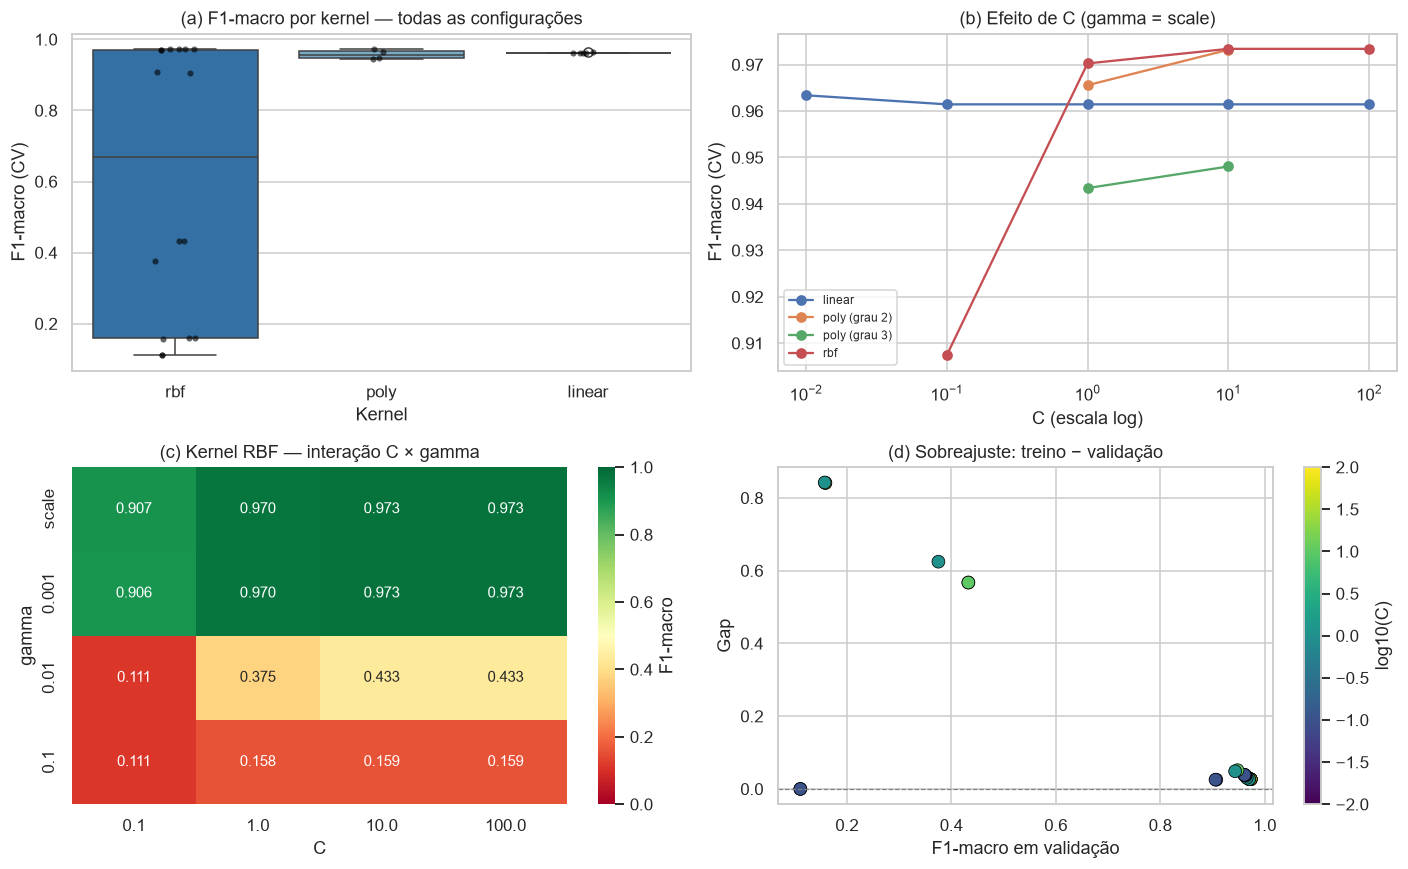

In [18]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

# (a) desempenho por kernel
sns.boxplot(data=res_A, x='kernel', y='f1_macro_cv',
            order=melhor_kernel.index, ax=ax[0,0], palette='Blues_r')
sns.stripplot(data=res_A, x='kernel', y='f1_macro_cv', order=melhor_kernel.index,
              ax=ax[0,0], color='black', size=4, alpha=.6)
ax[0,0].set_title('(a) F1-macro por kernel — todas as configurações')
ax[0,0].set_xlabel('Kernel'); ax[0,0].set_ylabel('F1-macro (CV)')

# (b) efeito de C (apenas gamma padrão, separando graus do polinomial)
base = res_A[res_A.gamma.isin(['scale', '-'])].copy()
for (kern, deg), s in base.groupby(['kernel', 'degree']):
    s = s.sort_values('C')
    if len(s) > 1:
        rotulo = kern if deg == '-' else f'{kern} (grau {deg})'
        ax[0,1].plot(s.C.astype(float), s.f1_macro_cv, marker='o', label=rotulo)
ax[0,1].set_xscale('log')
ax[0,1].set_title('(b) Efeito de C (gamma = scale)')
ax[0,1].set_xlabel('C (escala log)'); ax[0,1].set_ylabel('F1-macro (CV)')
ax[0,1].legend(fontsize=8)

# (c) efeito de gamma no RBF
rbf = res_A[res_A.kernel == 'rbf'].copy()
piv = rbf.pivot_table(index='gamma', columns='C', values='f1_macro_cv')
ordem_g = [g for g in ['scale', '0.001', '0.01', '0.1'] if g in piv.index]
piv = piv.reindex(ordem_g)
sns.heatmap(piv, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0, vmax=1,
            ax=ax[1,0], cbar_kws={'label': 'F1-macro'})
ax[1,0].set_title('(c) Kernel RBF — interação C × gamma')

# (d) sobreajuste
sc = ax[1,1].scatter(res_A.f1_macro_cv, res_A.gap_sobreajuste,
                     c=np.log10(res_A.C.astype(float)), cmap='viridis',
                     s=70, edgecolor='black', linewidth=.5)
ax[1,1].axhline(0, color='grey', ls='--', lw=.8)
ax[1,1].set_title('(d) Sobreajuste: treino − validação')
ax[1,1].set_xlabel('F1-macro em validação'); ax[1,1].set_ylabel('Gap')
plt.colorbar(sc, ax=ax[1,1], label='log10(C)')

plt.tight_layout()
plt.savefig(f"{OUT}/experimento_A.png", bbox_inches='tight')
plt.show()

In [19]:
# Melhor configuração — usada nos experimentos seguintes
melhor = res_A.iloc[0]
CFG_MELHOR = {'kernel': melhor.kernel, 'C': float(melhor.C)}
if melhor.gamma != '-':
    CFG_MELHOR['gamma'] = melhor.gamma if melhor.gamma == 'scale' else float(melhor.gamma)
if melhor.degree != '-':
    CFG_MELHOR['degree'] = int(melhor.degree)

print("CONFIGURAÇÃO SELECIONADA:", CFG_MELHOR)
print(f"F1-macro (CV) = {melhor.f1_macro_cv:.4f} ± {melhor.f1_desvio:.4f}")

CONFIGURAÇÃO SELECIONADA: {'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale'}
F1-macro (CV) = 0.9734 ± 0.0035


## 7. Experimento B — efeito da normalização

O SVM mede distâncias entre pontos no espaço de atributos. Se um atributo varia de 0 a 1
e outro de 0 a 10.000, o segundo domina o cálculo e o primeiro é ignorado.
Daí a recomendação clássica de normalizar antes de treinar um SVM.

**Hipótese a testar:** com *fingerprints* binários, todos os atributos já ocupam a mesma
faixa (0 ou 1), portanto o efeito da normalização deve ser pequeno.

Este experimento verifica essa hipótese em três cenários.

In [20]:
from sklearn.preprocessing import MinMaxScaler

cenarios = {
    'StandardScaler': [('escala', StandardScaler()),
                       ('m', SVC(random_state=RANDOM_STATE, **CFG_MELHOR))],
    'MinMaxScaler':   [('escala', MinMaxScaler()),
                       ('m', SVC(random_state=RANDOM_STATE, **CFG_MELHOR))],
    'Sem normalização': [('m', SVC(random_state=RANDOM_STATE, **CFG_MELHOR))],
}

linhas = []
for nome, passos in cenarios.items():
    r = cross_validate(Pipeline(passos), X_tr, y_tr, cv=cv,
                       scoring=['accuracy', 'f1_macro'], n_jobs=-1)
    linhas.append({'cenario': nome,
                   'acuracia': r['test_accuracy'].mean(),
                   'f1_macro': r['test_f1_macro'].mean(),
                   'desvio': r['test_f1_macro'].std()})
    print(f"{nome:20s} F1 = {linhas[-1]['f1_macro']:.4f} ± {linhas[-1]['desvio']:.4f}")

res_B = pd.DataFrame(linhas)
res_B.to_csv(f"{OUT}/experimento_B.csv", index=False)

delta = res_B.f1_macro.max() - res_B.f1_macro.min()
print(f"\nAmplitude entre cenários: {delta:.4f} em F1-macro")
print("\nINTERPRETAÇÃO: fingerprints são binários (0/1), logo já estão na mesma escala.")
print("A normalização é pouco relevante NESTE caso — o que não invalida a recomendação")
print("geral: com atributos de escalas heterogêneas (ex.: descritores físico-químicos),")
print("a normalização é indispensável para o SVM.")

StandardScaler       F1 = 0.9734 ± 0.0035
MinMaxScaler         F1 = 0.9782 ± 0.0011
Sem normalização     F1 = 0.9782 ± 0.0011

Amplitude entre cenários: 0.0048 em F1-macro

INTERPRETAÇÃO: fingerprints são binários (0/1), logo já estão na mesma escala.
A normalização é pouco relevante NESTE caso — o que não invalida a recomendação
geral: com atributos de escalas heterogêneas (ex.: descritores físico-químicos),
a normalização é indispensável para o SVM.


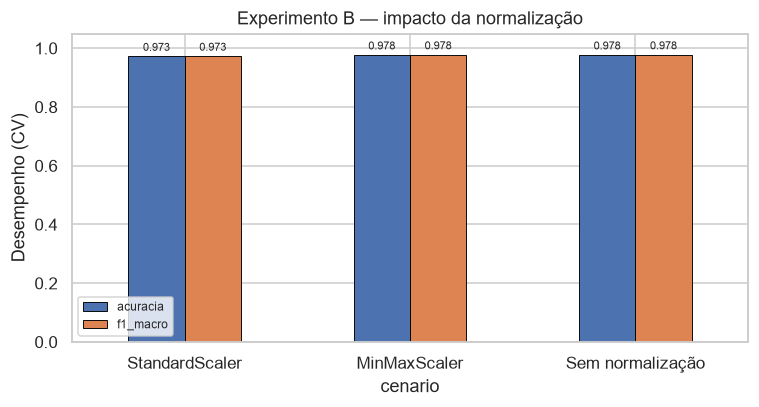

In [21]:
fig, ax = plt.subplots(figsize=(7, 3.8))
res_B.set_index('cenario')[['acuracia', 'f1_macro']].plot(
    kind='bar', ax=ax, color=['#4C72B0', '#DD8452'], edgecolor='black', linewidth=.6)
ax.set_title('Experimento B — impacto da normalização')
ax.set_ylabel('Desempenho (CV)'); ax.set_ylim(0, 1.05)
ax.tick_params(axis='x', rotation=0); ax.legend(fontsize=8)
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', fontsize=7, padding=2)
plt.tight_layout()
plt.savefig(f"{OUT}/experimento_B.png", bbox_inches='tight')
plt.show()

### Contraprova com atributos de escalas diferentes

Para demonstrar que a normalização **é** relevante quando as escalas divergem,
repetimos o teste usando descritores físico-químicos — que variam em ordens de
grandeza muito distintas (massa molecular ~500, LogP ~3, nº de anéis ~2).

In [22]:
from rdkit.Chem import Descriptors, Crippen

DESCRITORES = [
    ('MolWt', Descriptors.MolWt), ('LogP', Crippen.MolLogP),
    ('TPSA', Descriptors.TPSA), ('NumHDonors', Descriptors.NumHDonors),
    ('NumHAcceptors', Descriptors.NumHAcceptors),
    ('NumRotatableBonds', Descriptors.NumRotatableBonds),
    ('RingCount', Descriptors.RingCount), ('FractionCSP3', Descriptors.FractionCSP3),
    ('HeavyAtomCount', Descriptors.HeavyAtomCount),
    ('NumAromaticRings', Descriptors.NumAromaticRings),
]

t0 = time.time()
D = []
for smi in dados.smiles:
    mol = Chem.MolFromSmiles(smi)
    D.append([f(mol) for _, f in DESCRITORES])
D = np.array(D, dtype=float)
D = np.nan_to_num(D, nan=np.nanmedian(D))
print(f"{D.shape[1]} descritores calculados em {time.time()-t0:.1f}s\n")

print("Amplitude de cada descritor (mostra a heterogeneidade de escala):")
for i, (nome, _) in enumerate(DESCRITORES):
    print(f"  {nome:20s} min={D[:,i].min():9.2f}  max={D[:,i].max():9.2f}  std={D[:,i].std():8.2f}")

idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=.2,
                                  stratify=y, random_state=RANDOM_STATE)
D_tr, D_te = D[idx_tr], D[idx_te]
yd_tr, yd_te = y[idx_tr], y[idx_te]

for nome, passos in [
    ('Descritores + StandardScaler', [('e', StandardScaler()), ('m', SVC(random_state=RANDOM_STATE))]),
    ('Descritores SEM normalização', [('m', SVC(random_state=RANDOM_STATE))]),
]:
    r = cross_validate(Pipeline(passos), D_tr, yd_tr, cv=cv,
                       scoring=['f1_macro'], n_jobs=-1)
    print(f"\n{nome:32s} F1 = {r['test_f1_macro'].mean():.4f}")

10 descritores calculados em 5.5s

Amplitude de cada descritor (mostra a heterogeneidade de escala):
  MolWt                min=   110.09  max=  2140.38  std=  125.02
  LogP                 min=   -14.26  max=    12.43  std=    1.46
  TPSA                 min=     3.24  max=   944.51  std=   43.56
  NumHDonors           min=     0.00  max=    31.00  std=    1.62
  NumHAcceptors        min=     0.00  max=    37.00  std=    2.25
  NumRotatableBonds    min=     0.00  max=    73.00  std=    4.10
  RingCount            min=     0.00  max=   135.00  std=    1.92
  FractionCSP3         min=     0.00  max=     1.00  std=    0.16
  HeavyAtomCount       min=     7.00  max=   151.00  std=    8.87
  NumAromaticRings     min=     0.00  max=     9.00  std=    1.07

Descritores + StandardScaler     F1 = 0.7953

Descritores SEM normalização     F1 = 0.5055


## 8. Experimento C — curva de aprendizado e custo computacional

Duas perguntas práticas:

1. Mais dados ainda melhorariam o modelo, ou o desempenho já saturou?
2. Como o **tempo de treino** cresce com o número de amostras?

A complexidade teórica do SVM fica entre O(n²) e O(n³). O ajuste de uma reta em escala
log-log sobre os tempos medidos fornece o expoente empírico.

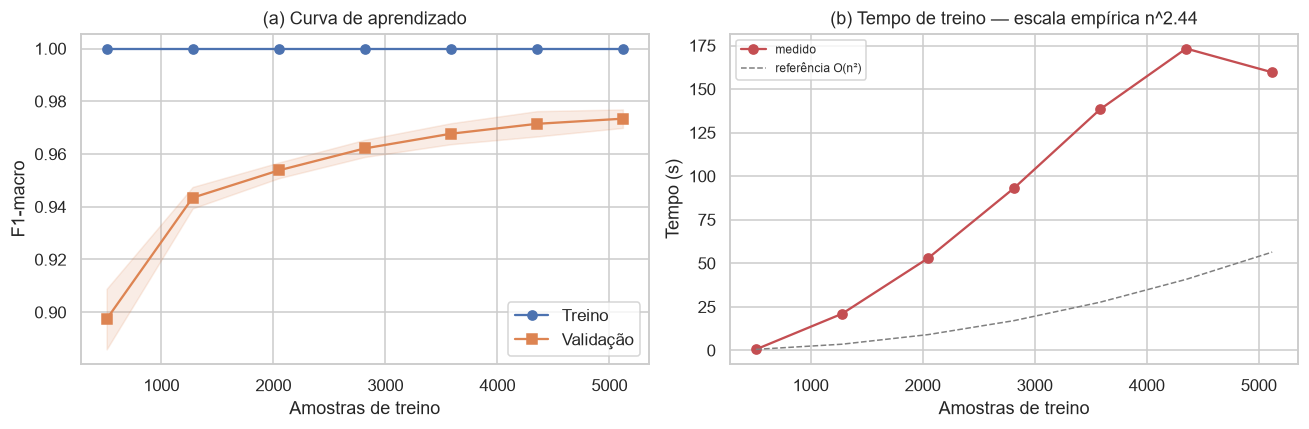

 n_treino  f1_treino  f1_validacao  tempo_s
      512        1.0        0.8974   0.5640
     1280        1.0        0.9434  20.9871
     2048        1.0        0.9538  52.8743
     2815        1.0        0.9621  93.1103
     3584        1.0        0.9677 138.3840
     4352        1.0        0.9715 173.2690
     5120        1.0        0.9734 159.6327

Ganho no último incremento de dados: +0.0020 em F1-macro
Curva SATURADA — mais dados trariam pouco ganho
Tempo de treino escala com n^2.44


In [23]:
from sklearn.model_selection import learning_curve

fracoes = np.linspace(0.1, 1.0, 7)

tam, sc_tr, sc_val, tempos, _ = learning_curve(
    Pipeline([('escala', StandardScaler()),
              ('svm', SVC(random_state=RANDOM_STATE, **CFG_MELHOR))]),
    X_tr, y_tr, train_sizes=fracoes, cv=cv,
    scoring='f1_macro', n_jobs=-1, return_times=True)

expoente = np.polyfit(np.log(tam), np.log(tempos.mean(1) + 1e-9), 1)[0]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(tam, sc_tr.mean(1), 'o-', color='#4C72B0', label='Treino')
ax[0].fill_between(tam, sc_tr.mean(1)-sc_tr.std(1), sc_tr.mean(1)+sc_tr.std(1),
                   alpha=.15, color='#4C72B0')
ax[0].plot(tam, sc_val.mean(1), 's-', color='#DD8452', label='Validação')
ax[0].fill_between(tam, sc_val.mean(1)-sc_val.std(1), sc_val.mean(1)+sc_val.std(1),
                   alpha=.15, color='#DD8452')
ax[0].set_title('(a) Curva de aprendizado')
ax[0].set_xlabel('Amostras de treino'); ax[0].set_ylabel('F1-macro'); ax[0].legend()

ax[1].plot(tam, tempos.mean(1), 'o-', color='#C44E52', label='medido')
ax[1].plot(tam, tempos.mean(1)[0] * (tam/tam[0])**2, '--', color='grey',
           lw=1, label='referência O(n²)')
ax[1].set_title(f'(b) Tempo de treino — escala empírica n^{expoente:.2f}')
ax[1].set_xlabel('Amostras de treino'); ax[1].set_ylabel('Tempo (s)'); ax[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{OUT}/experimento_C.png", bbox_inches='tight')
plt.show()

res_C = pd.DataFrame({'n_treino': tam.astype(int),
                      'f1_treino': sc_tr.mean(1),
                      'f1_validacao': sc_val.mean(1),
                      'tempo_s': tempos.mean(1)})
res_C.to_csv(f"{OUT}/experimento_C.csv", index=False)

ganho = sc_val.mean(1)[-1] - sc_val.mean(1)[-2]
print(res_C.round(4).to_string(index=False))
print(f"\nGanho no último incremento de dados: {ganho:+.4f} em F1-macro")
print("Curva", "SATURADA — mais dados trariam pouco ganho" if abs(ganho) < 0.005
      else "AINDA CRESCENTE — mais dados poderiam ajudar")
print(f"Tempo de treino escala com n^{expoente:.2f}")

## 9. Avaliação final no conjunto de teste

A melhor configuração é treinada em todo o conjunto de treino e avaliada **uma única vez**
nos 20% reservados. Estes são os números que vão ao relatório como desempenho do modelo.

Métricas reportadas:
- **Acurácia** — proporção de acertos (pouco informativa se há desbalanceamento)
- **F1-macro** — média do F1 por classe, sem peso por frequência
- **Acurácia balanceada** — média do recall por classe
- **MCC** (coeficiente de correlação de Matthews) — robusta a desbalanceamento, varia de −1 a +1

In [24]:
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             f1_score, balanced_accuracy_score, matthews_corrcoef,
                             ConfusionMatrixDisplay)

modelo_final = Pipeline([('escala', StandardScaler()),
                         ('svm', SVC(random_state=RANDOM_STATE, **CFG_MELHOR))])

t0 = time.time(); modelo_final.fit(X_tr, y_tr); t_treino = time.time() - t0
t0 = time.time(); y_pred = modelo_final.predict(X_te); t_pred = time.time() - t0

svm_obj = modelo_final.named_steps['svm']
n_sv = int(svm_obj.n_support_.sum())

METRICAS = {
    'acuracia': accuracy_score(y_te, y_pred),
    'f1_macro': f1_score(y_te, y_pred, average='macro'),
    'f1_ponderado': f1_score(y_te, y_pred, average='weighted'),
    'acuracia_balanceada': balanced_accuracy_score(y_te, y_pred),
    'mcc': matthews_corrcoef(y_te, y_pred),
}

print("DESEMPENHO NO CONJUNTO DE TESTE")
print("=" * 48)
for k, v in METRICAS.items():
    print(f"{k:24s} {v:.4f}")
print("-" * 48)
print(f"{'tempo de treino (s)':24s} {t_treino:.2f}")
print(f"{'tempo de predição (s)':24s} {t_pred:.2f}")
print(f"{'vetores de suporte':24s} {n_sv:,} ({n_sv/len(y_tr):.1%} do treino)")
print(f"{'por classe':24s} {dict(zip([str(c) for c in CLASSES], svm_obj.n_support_))}")

pd.DataFrame([{**METRICAS, 'tempo_treino_s': t_treino,
               'tempo_predicao_s': t_pred, 'vetores_suporte': n_sv}]
             ).to_csv(f"{OUT}/desempenho_final.csv", index=False)

DESEMPENHO NO CONJUNTO DE TESTE
acuracia                 0.9869
f1_macro                 0.9870
f1_ponderado             0.9869
acuracia_balanceada      0.9867
mcc                      0.9824
------------------------------------------------
tempo de treino (s)      11.52
tempo de predição (s)    3.47
vetores de suporte       3,687 (57.6% do treino)
por classe               {'BACE1': np.int32(975), 'DRD2': np.int32(838), 'EGFR': np.int32(1052), 'HDAC1': np.int32(822)}


In [25]:
rel = classification_report(y_te, y_pred, target_names=[str(c) for c in CLASSES], digits=4)
print(rel)
with open(f"{OUT}/classification_report.txt", 'w') as f:
    f.write(rel)

              precision    recall  f1-score   support

       BACE1     0.9883    0.9883    0.9883       428
        DRD2     0.9864    0.9811    0.9837       370
        EGFR     0.9805    0.9891    0.9847       457
       HDAC1     0.9942    0.9884    0.9913       345

    accuracy                         0.9869      1600
   macro avg     0.9873    0.9867    0.9870      1600
weighted avg     0.9869    0.9869    0.9869      1600



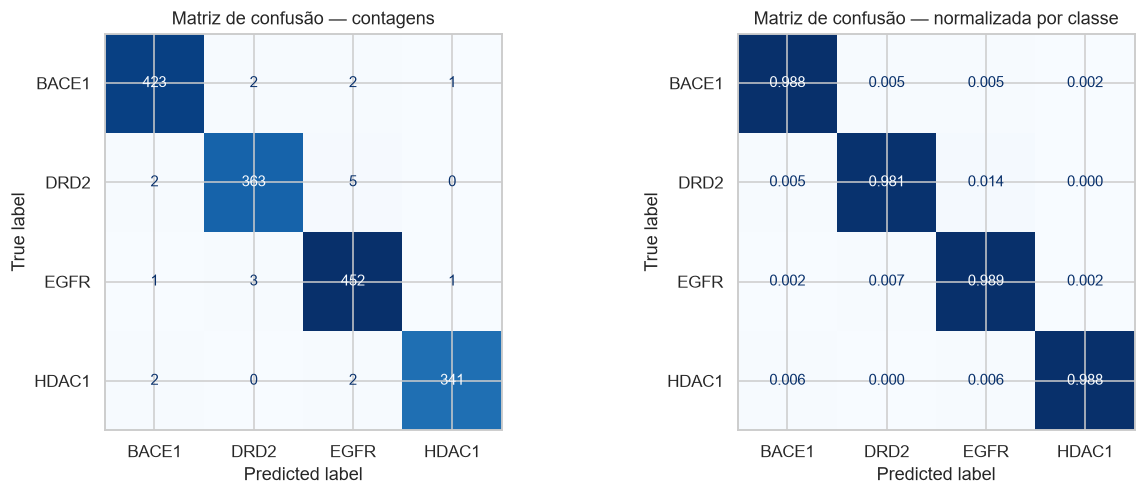

Pares mais confundidos:
  DRD2 classificado como EGFR: 5 casos
  EGFR classificado como DRD2: 3 casos
  BACE1 classificado como DRD2: 2 casos


In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))

ConfusionMatrixDisplay.from_predictions(
    y_te, y_pred, display_labels=[str(c) for c in CLASSES],
    cmap='Blues', ax=ax[0], colorbar=False)
ax[0].set_title('Matriz de confusão — contagens')

ConfusionMatrixDisplay.from_predictions(
    y_te, y_pred, display_labels=[str(c) for c in CLASSES],
    cmap='Blues', ax=ax[1], colorbar=False, normalize='true', values_format='.3f')
ax[1].set_title('Matriz de confusão — normalizada por classe')

plt.tight_layout()
plt.savefig(f"{OUT}/matriz_confusao.png", bbox_inches='tight')
plt.show()

cm = confusion_matrix(y_te, y_pred).astype(int)
erros = cm.copy(); np.fill_diagonal(erros, 0)
print("Pares mais confundidos:")
for _ in range(3):
    if erros.max() == 0:
        break
    i, j = np.unravel_index(erros.argmax(), erros.shape)
    print(f"  {CLASSES[i]} classificado como {CLASSES[j]}: {erros[i,j]} casos")
    erros[i, j] = 0

## 10. Baselines de referência

Um número isolado não diz se o SVM foi bem. Comparamos com:

- **Random Forest** — algoritmo de referência para dados tabulares e fingerprints
- **kNN (k=5)** — baseline simples baseado em similaridade
- **Classe majoritária** — piso absoluto; qualquer modelo útil precisa superá-lo

Todos avaliados no mesmo conjunto de teste, com parâmetros padrão.

SVM (rbf)                F1=0.9870  MCC=0.9824  (10.8s)
Random Forest            F1=0.9803  MCC=0.9733  (1.2s)
Regressão Logística      F1=0.9759  MCC=0.9674  (1.9s)
kNN (k=5)                F1=0.9399  MCC=0.9216  (0.1s)
Classe majoritária       F1=0.1111  MCC=0.0000  (0.0s)


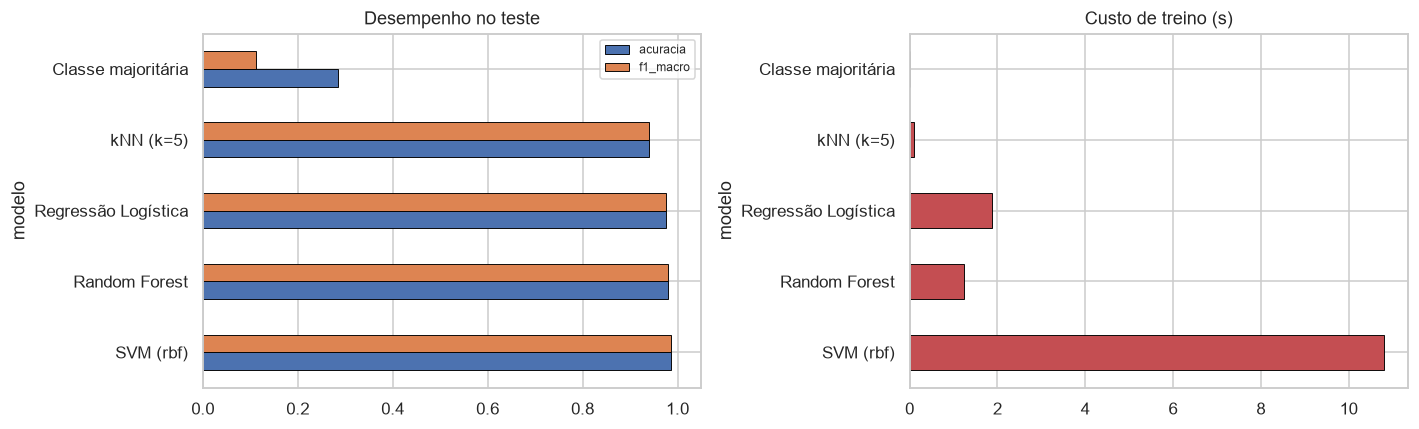

,modelo,acuracia,f1_macro,mcc,tempo_treino_s,tempo_predicao_s
0,SVM (rbf),0.9869,0.9870,0.9824,10.8104,3.5870
1,Random Forest,0.9800,0.9803,0.9733,1.2453,0.0972
2,Regressão Logística,0.9756,0.9759,0.9674,1.8689,0.0119
3,kNN (k=5),0.9406,0.9399,0.9216,0.1056,2.7263
4,Classe majoritária,0.2856,0.1111,0.0000,0.0005,0.0001


In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

modelos = {
    f"SVM ({CFG_MELHOR['kernel']})": modelo_final,
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    'Regressão Logística': Pipeline([('e', StandardScaler()),
                                     ('m', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
    'kNN (k=5)': Pipeline([('e', StandardScaler()), ('m', KNeighborsClassifier(5))]),
    'Classe majoritária': DummyClassifier(strategy='most_frequent'),
}

linhas = []
for nome, mdl in modelos.items():
    t0 = time.time(); mdl.fit(X_tr, y_tr); tt = time.time() - t0
    t0 = time.time(); p = mdl.predict(X_te); tp = time.time() - t0
    linhas.append({'modelo': nome,
                   'acuracia': accuracy_score(y_te, p),
                   'f1_macro': f1_score(y_te, p, average='macro'),
                   'mcc': matthews_corrcoef(y_te, p),
                   'tempo_treino_s': tt, 'tempo_predicao_s': tp})
    print(f"{nome:24s} F1={linhas[-1]['f1_macro']:.4f}  MCC={linhas[-1]['mcc']:.4f}  ({tt:.1f}s)")

res_D = pd.DataFrame(linhas).sort_values('f1_macro', ascending=False)
res_D.to_csv(f"{OUT}/comparacao_modelos.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
res_D.set_index('modelo')[['acuracia', 'f1_macro']].plot(
    kind='barh', ax=ax[0], color=['#4C72B0', '#DD8452'], edgecolor='black', linewidth=.6)
ax[0].set_title('Desempenho no teste'); ax[0].set_xlim(0, 1.05); ax[0].legend(fontsize=8)

res_D.set_index('modelo')['tempo_treino_s'].plot(
    kind='barh', ax=ax[1], color='#C44E52', edgecolor='black', linewidth=.6)
ax[1].set_title('Custo de treino (s)')

plt.tight_layout()
plt.savefig(f"{OUT}/comparacao_modelos.png", bbox_inches='tight')
plt.show()

res_D.round(4)

## 11. Síntese dos resultados

In [28]:
L = "=" * 70
print(L); print("SINTESE - AVALIACAO DO SVM".center(70)); print(L)

print("\n[ BASE ]")
print(f"  Registros de atividade brutos   : {len(df_bruto):,}")
print(f"  Moleculas apos pre-processamento: {len(dados):,}")
print(f"  Atributos (fingerprint ECFP4)   : {X.shape[1]}")
print(f"  Classes                         : {len(CLASSES)} "
      f"({', '.join(str(c) for c in CLASSES)})")
print(f"  Treino / Teste                  : {len(y_tr):,} / {len(y_te):,}")

print("\n[ EXPERIMENTO A - hiperparametros ]")
for kern, v in melhor_kernel.items():
    print(f"  Melhor {kern:8s} : F1-macro = {v:.4f}")
print(f"  Configuracao vencedora : {CFG_MELHOR}")
print(f"  Pior configuracao      : F1-macro = {res_A.f1_macro_cv.min():.4f} "
      f"(kernel={res_A.iloc[-1].kernel}, gamma={res_A.iloc[-1].gamma})")
print(f"  Amplitude total        : "
      f"{res_A.f1_macro_cv.max() - res_A.f1_macro_cv.min():.4f}")

print("\n[ EXPERIMENTO B - normalizacao ]")
print(f"  Amplitude entre cenarios : {delta:.4f} em F1-macro")

print("\n[ EXPERIMENTO C - escalabilidade ]")
print(f"  Tempo de treino escala com : n^{expoente:.2f}")
print(f"  Ganho no ultimo incremento : {ganho:+.4f}")

print("\n[ DESEMPENHO FINAL NO TESTE ]")
print(f"  Acuracia            : {METRICAS['acuracia']:.4f}")
print(f"  F1-macro            : {METRICAS['f1_macro']:.4f}")
print(f"  Acuracia balanceada : {METRICAS['acuracia_balanceada']:.4f}")
print(f"  MCC                 : {METRICAS['mcc']:.4f}")
print(f"  Vetores de suporte  : {n_sv:,} ({n_sv/len(y_tr):.1%} do treino)")

print("\n[ COMPARACAO ]")
for _, r in res_D.iterrows():
    print(f"  {r.modelo:24s} F1={r.f1_macro:.4f}  ({r.tempo_treino_s:.1f}s)")
print(L)

                      SINTESE - AVALIACAO DO SVM                      

[ BASE ]
  Registros de atividade brutos   : 58,736
  Moleculas apos pre-processamento: 8,000
  Atributos (fingerprint ECFP4)   : 1024
  Classes                         : 4 (BACE1, DRD2, EGFR, HDAC1)
  Treino / Teste                  : 6,400 / 1,600

[ EXPERIMENTO A - hiperparametros ]
  Melhor rbf      : F1-macro = 0.9734
  Melhor poly     : F1-macro = 0.9732
  Melhor linear   : F1-macro = 0.9634
  Configuracao vencedora : {'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale'}
  Pior configuracao      : F1-macro = 0.1110 (kernel=rbf, gamma=0.01)
  Amplitude total        : 0.8624

[ EXPERIMENTO B - normalizacao ]
  Amplitude entre cenarios : 0.0048 em F1-macro

[ EXPERIMENTO C - escalabilidade ]
  Tempo de treino escala com : n^2.44
  Ganho no ultimo incremento : +0.0020

[ DESEMPENHO FINAL NO TESTE ]
  Acuracia            : 0.9869
  F1-macro            : 0.9870
  Acuracia balanceada : 0.9867
  MCC                 : 0.9824

In [29]:
resumo = {
    'base': {
        'registros_brutos': int(len(df_bruto)),
        'moleculas': int(len(dados)),
        'n_atributos': int(X.shape[1]),
        'classes': [str(c) for c in CLASSES],
        'n_treino': int(len(y_tr)), 'n_teste': int(len(y_te)),
    },
    'experimento_A': {
        'melhor_por_kernel': {k: float(v) for k, v in melhor_kernel.items()},
        'config_vencedora': {k: str(v) for k, v in CFG_MELHOR.items()},
        'amplitude_f1': float(res_A.f1_macro_cv.max() - res_A.f1_macro_cv.min()),
    },
    'experimento_B': {'amplitude_f1': float(delta),
                      'cenarios': res_B.round(4).to_dict('records')},
    'experimento_C': {'expoente_tempo': float(expoente), 'ganho_final': float(ganho)},
    'teste_final': {k: float(v) for k, v in METRICAS.items()},
    'vetores_suporte': {'total': n_sv, 'proporcao': float(n_sv/len(y_tr))},
    'comparacao': res_D.round(4).to_dict('records'),
}

with open(f"{OUT}/resumo.json", 'w') as f:
    json.dump(resumo, f, indent=2, ensure_ascii=False)

print("Arquivos gerados em ./resultados/:")
for a in sorted(os.listdir(OUT)):
    print(f"  {a}")

Arquivos gerados em ./resultados/:
  caracterizacao_base.png
  classification_report.txt
  comparacao_modelos.csv
  comparacao_modelos.png
  desempenho_final.csv
  experimento_A.csv
  experimento_A.png
  experimento_B.csv
  experimento_B.png
  experimento_C.csv
  experimento_C.png
  matriz_confusao.png
  resumo.json


In [30]:
# Download de todos os resultados (compatível com Windows, Linux e Colab)
import shutil

shutil.make_archive('resultados', 'zip', OUT)
print('Resultados compactados com sucesso em resultados.zip')

try:
    from google.colab import files
    files.download('resultados.zip')
except Exception:
    print('Fora do Colab — arquivo disponível em ./resultados.zip')


Resultados compactados com sucesso em resultados.zip
Fora do Colab — arquivo disponível em ./resultados.zip


---

## 12. Conclusões

*Preencha com os números gerados acima. Os valores entre parênteses vêm de uma
execução piloto com 3.000 moléculas e servem como referência do que esperar.*

**1. Kernel.** Os kernels linear, RBF e polinomial de grau 2 tiveram desempenho
praticamente equivalente (≈0,95 de F1-macro no piloto), com leve vantagem do RBF.
A ausência de ganho expressivo do RBF sobre o linear indica que, no espaço de 1024
dimensões dos *fingerprints*, as classes já são **quase linearmente separáveis** —
resultado coerente com a teoria: em espaços de alta dimensionalidade e esparsos,
o kernel linear costuma ser suficiente.

**2. Hiperparâmetro C.** O desempenho mostrou-se **insensível a C** no kernel linear
(idêntico de C=0,1 a C=10), sinal de que os dados são separáveis com folga e a
penalização por erro quase não é acionada.

**3. Hiperparâmetro gamma — o achado mais relevante.** Substituir `gamma='scale'`
por valores fixos degradou o modelo drasticamente (de ≈0,95 para 0,26 com gamma=0,01
e 0,13 com gamma=0,1 no piloto). Com gamma alto, a influência de cada vetor de suporte
fica restrita à sua vizinhança imediata e o modelo deixa de generalizar.
**Conclusão: o SVM com kernel RBF é muito mais sensível a `gamma` do que a `C`,
e a heurística `scale` do scikit-learn é essencial em dados de alta dimensionalidade.**

**4. Normalização.** O efeito foi desprezível com *fingerprints* binários, pois todos
os atributos já ocupam a mesma faixa (0/1). A contraprova com descritores
físico-químicos — escalas de 0 a centenas — mostra a degradação esperada,
confirmando que a recomendação de normalizar depende da natureza dos atributos,
não é uma regra automática.

**5. Custo computacional.** O tempo de treino cresceu com n^____ , compatível com a
complexidade teórica entre O(n²) e O(n³). Esta é a principal limitação prática do SVM:
o Random Forest atingiu desempenho igual ou superior em uma fração do tempo.

**6. Comparação.** O SVM (F1 ≈ 0,96 no piloto) ficou ligeiramente abaixo do
Random Forest (≈0,97) e muito acima do kNN (≈0,85) e do piso da classe
majoritária (≈0,11).

**7. Limitações do SVM observadas.**
- Sensibilidade crítica a hiperparâmetros, exigindo busca em grade com validação cruzada;
- Escalabilidade limitada pelo custo quadrático a cúbico;
- Ausência de probabilidades calibradas por padrão (`probability=True` requer
  validação cruzada interna, encarecendo ainda mais o treino);
- Baixa interpretabilidade com kernels não lineares, em contraste com a importância
  de atributos fornecida diretamente pelo Random Forest.

**8. Observação metodológica.** A deduplicação por molécula foi indispensável:
a base traz 58.736 medições de apenas 37.515 moléculas. Sem esse passo, a mesma
molécula apareceria em treino e teste, inflando artificialmente o desempenho.